# Refined-study review and visualization handoff

For completed F/AC sweeps use `SWEEP_MODE="skip"` to read the existing CSV quickly; `"analyze"` recomputes metrics from saved data without running the solver. Default export is five PDF maps only. `PLOT_ALL_DIAGNOSTICS=True` restores the larger diagnostic set. All calculated metrics remain in reports. Select IDs manually after reviewing tables; the final cell exports a study/report-specific manifest for `strain_coupling_visualization.ipynb`. No animation selection is automatic.

# Strain-orientation coupling: broad grid and targeted neighborhoods

`REFINED_STUDY="F"` selects 36 F-neighborhood cases; `"AC"` combines the original 36 A–C cases with nine weak-activity cases. Only the nine additions are eligible for execution. Set it to `None` to restore the original broad grid/scan/relaxation controls. The solver, boundary conditions and fixed parameters are unchanged. Default mode is **preview**; it verifies reusable data and prints proposed commands without launching simulations or writing reports.

Each refined study uses its own `refined_F_tend5p0` / `refined_AC_tend5p0` output and figure directories and CSV prefix. Reuse searches recorded metadata across existing sweeps (including the original grid), pilot and validation runs; every fixed parameter, L/d0 consistency and all saved frames are checked. Existing data are never modified. Old metadata does not record source/BC hashes, so historical code identity cannot be certified from metadata alone.

Preview/analyze may take time because reuse verification reads full saved histories. Run mode retains batching/retry protections; skip reads reports only. Candidate labels for refined studies are configured through parameter tuples in `REFINED_ANNOTATIONS`, not historical A-H IDs.

# Strain–orientation coupling: progressive exploration

The current exploratory grid spans 9 gamma values × 7 activity values × 4 imposed strains = **252 cases**. Successful completion does not establish physical validity. The model is unchanged: $\lambda_c=0$, negative $\zeta_{\mathrm{eff}}$ is contractile, and $\varepsilon_0=d_0/(2L)$ sets the imposed nominal strain. Zero imposed displacement does not exclude activity-driven internal strain.

## Workflow

Use the WSL2 `fenicsx09` kernel and start Jupyter in the repository root. `SWEEP_MODE="preview"` prints commands without launching simulations or creating reports. Set it to `"run"` only when ready. `"analyze"` recomputes diagnostics from existing runs; `"skip"` loads CSVs only. Subprocesses use the kernel's Python and the existing `run_simulation.py`.

- `STUDY="scan"`: select `SCAN_PARAMETER`; vary its `SCAN_VALUES` while other parameters come from `BASE`. The smaller scan controls are retained for targeted checks.
- `STUDY="grid"`: use the Cartesian product of the three grid lists after selecting useful ranges.
- `STUDY="relaxation"`: explicitly select `RELAXATION_CASES` and a longer end time. These use separate folders and reports.

Expanded runs go under `outputs/strain_coupling/sweeps/<study>_tend<time>/`. Reports go under `analysis/`, figures under `figures/sweeps/`. Pilot files remain untouched. Complete matching attempts are reused; unsuccessful/mismatched attempts are retained and skipped by default. Set `RETRY_FAILED=True` to restart selected unsuccessful cases in fresh retry folders; this is a restart, not a checkpoint continuation. Analysis never launches retries. Inspect `run.log` for solver failures; do not assume a retry fixes a numerical problem.

Execution resets the in-memory mode to preview. Also restore the configuration cell to preview before saving. List disjoint CSV paths in `CSV_FILES` to compare several reports; use one latest report for overlapping grids. Different durations or fixed physical settings cannot be combined into one map.

Large responses, large deformation and numerical failure require different interpretations; none automatically establishes a phase transition. No convergence study is performed here.

## Current grid and batches

The defaults are `STUDY="grid"`, `SWEEP_MODE="preview"`, `BATCH_SIZE=21`, `BATCH_INDEX=0`. There are 12 batches, numbered 0–11. Ordering is epsilon0 outermost, gamma next, activity fastest. Each epsilon0 occupies 63 cases (three batches). Batch 0 covers epsilon0=0 and gamma=-8,-4,-2, each at all seven activities. Keep grid lists and their ordering unchanged while using these IDs.

Preview inspects the full grid without writing. Run mode executes only the selected batch. Increase `BATCH_INDEX` to proceed; rerunning a batch skips its completed cases. An interrupted/failed case is retried only with `RETRY_FAILED=True`, preserving its earlier attempt. `BATCH_SIZE=None, BATCH_INDEX=0` selects all 252, but batching is recommended for inspection between stages. Do not run multiple notebook instances against the same grid concurrently.

Each timestamped CSV includes all 252 rows and is updated atomically before/after each simulation. The next invocation reconstructs status from on-disk runs, including matching completed pilot/scan cases; all original outputs stay untouched. `SWEEP_MODE="analyze"` rebuilds the full-grid report without simulations. Load the latest report alone rather than concatenating overlapping batch reports. Numeric failure does not stop other cases in the batch. A manual interrupt stops the current child and batch; a hard kernel crash leaves an incomplete attempt to inspect. Optional `RUN_TIMEOUT_SECONDS` bounds a hanging run and records `timeout`; None imposes no limit.

Maps place the four epsilon0 slices in one figure per observable, using one shared color scale across the four panels. Comparisons across separate notebook invocations may rescale as more cases finish. Reference-area weighted metrics and saved-P1 screening diagnostics are retained. Red ! symbols mark completed cases with review flags; they remain valid numerical outputs, not automatically physical phases.


In [19]:
from pathlib import Path
from datetime import datetime, timezone
import csv
from itertools import product
import json
import shlex
import subprocess
import sys
from zipfile import BadZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Start Jupyter in the repository root, using the WSL2 fenicsx09 kernel.
ROOT = Path.cwd()
SWEEP_MODE = "run"  # "preview", "run", "analyze", or "skip"
REFINED_STUDY = "AC"  # "F", "AC", or None for the original studies
STUDY = "grid"          # "scan", "grid", or "relaxation"

# 1. Preliminary limit scans: change ONE parameter, keeping BASE fixed otherwise.
BASE = dict(epsilon0=0.05, gamma=0.5, zeta_eff=-0.6)
SCAN_PARAMETER = "gamma"  # or "zeta_eff" or "epsilon0"
SCAN_VALUES = {
    "gamma": [-2.0, -0.5, 0.0, 0.5, 2.0],  # later add -4, +4 if useful
    "zeta_eff": [-0.6, -1.0, -2.0],
    "epsilon0": [0.05, 0.10, 0.15],
}
# 2. Later Cartesian grids: illustrative ranges, not established physical limits.
EPSILON0_VALUES = [0.0, 0.05, 0.10, 0.20]
GAMMA_VALUES = [-8, -4, -2, -1, 0, 1, 2, 4, 8]
ZETA_EFF_VALUES = [0.0, -0.3, -0.6, -1.0, -2.0, -4.0, -8.0]
# Original broad-grid lists above remain available with REFINED_STUDY=None.
REFINED_GRIDS = {
    "F": dict(epsilon0=[0.025, 0.05, 0.10, 0.20], gamma=[-10, -8, -6], zeta_eff=[0, -0.15, -0.3]),
    "AC": dict(epsilon0=[0.025, 0.05], gamma=[0, 0.25, 0.5, 1, 1.5, 2], zeta_eff=[0, -0.3, -0.6]),
}
if REFINED_STUDY is not None:
    if REFINED_STUDY not in REFINED_GRIDS:
        raise ValueError("REFINED_STUDY must be F, AC or None")
    STUDY = "grid"
    chosen_grid = REFINED_GRIDS[REFINED_STUDY]
    EPSILON0_VALUES, GAMMA_VALUES, ZETA_EFF_VALUES = [chosen_grid[k] for k in ("epsilon0", "gamma", "zeta_eff")]
# Stable batches: epsilon0 outermost, gamma next, zeta_eff fastest.
AC_ADDITIONS = list(product([0.025], [0.0, 1.0, 2.0], [-0.05, -0.10, -0.20]))
BATCH_SIZE = None       # None selects the full grid
BATCH_INDEX = 0       # zero-based: 0..11 for this 252-case grid
RETRY_FAILED = False  # True restarts unsuccessful selected cases in NEW folders
RUN_TIMEOUT_SECONDS = None  # optional per-run wall-clock limit; no guessed default
CANDIDATE_LIMIT = 12
# 3. Optional longer runs: explicitly list selected cases and keep them separate.
RELAXATION_CASES = [dict(epsilon0=0.05, gamma=0.5, zeta_eff=-0.6)]
RELAXATION_T_END = 15.0
FIXED = dict(E=1.0, nu=0.3, xi=1.0, A=1.0, K=0.05, Gamma=1.0,
             T=5.0, dt=0.02, t_end=5.0, save_every=5, lambda_coupling=0.0)
if STUDY == "relaxation":
    FIXED["t_end"] = RELAXATION_T_END
STUDY_TAG = f"scan_{SCAN_PARAMETER}" if STUDY == "scan" else STUDY
if REFINED_STUDY is not None:
    STUDY_TAG = "refined_" + REFINED_STUDY
STUDY_TAG += "_tend" + str(FIXED["t_end"]).replace(".", "p")
OUTPUT_ROOT = ROOT / "outputs/strain_coupling/sweeps" / STUDY_TAG
ANALYSIS_DIR = ROOT / "outputs/strain_coupling/analysis"
FIGURE_DIR = ROOT / "outputs/strain_coupling/figures/sweeps" / STUDY_TAG
REPORT_PREFIX = "strain_coupling_" + STUDY_TAG
# Reuse only complete runs with matching recorded parameters; never edit these.
REUSE_ROOTS = [ROOT / "outputs/strain_coupling/pilot",
               ROOT / "outputs/strain_coupling/sweeps",
               ROOT / "outputs/strain_coupling/validation"]
# Read L without importing mesh_gen (which requires the simulation environment).
import ast
mesh_source = ast.parse((ROOT / "mesh_gen.py").read_text(encoding="utf-8"))
EXPECTED_L = next(ast.literal_eval(node.value) for node in mesh_source.body
                  if isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id == "L" for t in node.targets))
REUSE_INDEX = None  # Rebuilt after rerunning configuration; metadata-indexed, not name-dependent.

# Screening thresholds only: review flags, never physical phase boundaries.
STRAIN_REVIEW = 0.10  # Frobenius norm of symmetric saved-P1 displacement gradient
GRAD_REVIEW = 0.20    # Frobenius norm of saved-P1 displacement gradient
S_LOW_REVIEW = 0.10   # directors become ill-defined near zero order
S_HIGH_REVIEW = 2.0   # S > 1 alone is not considered invalid

# None loads the latest report for this study. Explicit paths can load older pilot CSVs.
if REFINED_STUDY == "AC":
    REPORT_PREFIX += "_combined45"
CSV_FILES = None
X_PARAMETER = "gamma"
Y_PARAMETER = "zeta_eff"
ABS_ACTIVITY_AXIS = True
FIXED_VALUES = None
SAVE_FIGURES = True
SHOW_SCREENING_FLAGS = False  # True restores red diagnostic markers; metrics stay unchanged.
MAKE_ANNOTATED_MAP = False     # Additional A-H version; ordinary maps are also saved.
PRESENTATION_CASES = {
    "A": (91, 0.05, 0, 0),
    "B": (81, 0.05, -2, -2),
    "C": (109, 0.05, 2, -2),
    "D": (117, 0.05, 4, -4),
    "E": (2, 0, -8, -0.6),
    "F": (189, 0.2, -8, 0),
    "G": (187, 0.1, 8, -4),
    "H": (188, 0.1, 8, -8),
}
# Refined labels are parameter tuples (epsilon0, gamma, zeta_eff), never old IDs.
REFINED_ANNOTATIONS = {}  # e.g. {"R1": (0.05, -8, 0)} for study F
if REFINED_STUDY is not None:
    PRESENTATION_CASES = {}
    MAKE_ANNOTATED_MAP = bool(REFINED_ANNOTATIONS)

PLOT_ALL_DIAGNOSTICS = False
DEFAULT_PLOT_METRICS = ["max_time_masked_mean_abs_dtheta", "mean_abs_dS",
                        "max_time_excluded_area_fraction", "max_time_strain_area_fraction",
                        "min_time_det_F_p1"]
SHOW_SELECTED_MARKERS = True  # Only on the primary masked director-response map.
CUSTOM_CASE_LABELS = {}  # Optional mapping, e.g. {0: "F_lowstrain"}; IDs belong to this report.

# Optional run IDs from the ranked table; nothing is selected automatically.
SELECTED_RUN_IDS = []  # Choose IDs from the loaded report after reviewing the candidates.
METRICS = ["mean_abs_dtheta", "max_abs_dtheta", "mean_abs_dS",
           "min_S", "max_S", "max_u", "max_vm"]
TIME_METRICS = ["max_time_mean_abs_dtheta", "time_max_mean_abs_dtheta",
                "peak_max_strain_p1", "peak_max_grad_u_p1", "peak_min_det_F_p1",
                "max_time_strain_p1", "max_time_grad_u_p1", "min_time_det_F_p1",
                "min_time_S", "max_time_S"]
COLUMNS = ["run_id", "epsilon0", "gamma", "zeta_eff", *FIXED, "L", "d0",
           "target_t", "actual_t", *METRICS, *TIME_METRICS, "review_flags", "diagnostic_method", "status", "message", "run_folder"]


ADDED_METRICS = ["masked_mean_abs_dtheta", "excluded_area_fraction",
                 "max_time_masked_mean_abs_dtheta", "max_time_excluded_area_fraction",
                 "peak_strain_area_fraction", "peak_gradient_area_fraction",
                 "max_time_strain_area_fraction", "max_time_gradient_area_fraction"]
COLUMNS += ADDED_METRICS


## Sweep and diagnostic helpers

Execute these definitions once; they do not launch simulations.


In [20]:
class RunIssue(Exception):
    def __init__(self, status, message):
        super().__init__(message)
        self.status = status


def number_tag(value):
    # repr keeps distinct finite float inputs distinct (including extended grids).
    return repr(float(value) if value != 0 else 0.0).replace("-", "m").replace("+", "p").replace(".", "p")


def run_name(parameters):
    return "run_" + "_".join(
        name + number_tag(parameters[key])
        for name, key in (("eps", "epsilon0"), ("gam", "gamma"), ("ze", "zeta_eff"))
    )


def command_for(parameters, folder):
    command = [sys.executable, "-u", str(ROOT / "run_simulation.py")]
    for key, value in parameters.items():
        command.extend(["--" + key, str(value)])
    return command + ["--outdir", str(folder)]


def spatial_weights(coords, triangles):
    """Lumped reference-area weights: each triangle contributes area/3 per node.

    This integrates the nodal interpolant of each scalar diagnostic, rather
    than taking a mesh-density-biased nodal average.
    """
    if (triangles.ndim != 2 or triangles.shape[1] != 3 or triangles.size == 0
            or not np.issubdtype(triangles.dtype, np.integer)):
        raise ValueError("Expected integer triangular connectivity")
    if triangles.min() < 0 or triangles.max() >= len(coords):
        raise ValueError("Connectivity does not index the saved coordinates")
    points = coords[triangles]
    edges = points[:, 1:] - points[:, :1]
    det = edges[:, 0, 0] * edges[:, 1, 1] - edges[:, 0, 1] * edges[:, 1, 0]
    scale = np.max(np.sum(edges**2, axis=2), axis=1)
    if np.any(np.abs(det) <= 100 * np.finfo(float).eps * scale):
        raise ValueError("Degenerate reference triangle")
    weights = np.zeros(len(coords))
    np.add.at(weights, triangles.ravel(), np.repeat(np.abs(det) / 6, 3))
    if np.any(weights == 0):
        raise ValueError("Saved nodes are missing from connectivity")
    return weights


def area_diagnostics(initial, snap, triangles):
    """Conservative whole-cell low-S mask, using reference triangle areas.

    A cell is excluded if ANY vertex has S<0.1 initially or currently.
    Thus no retained P1 cell contains interpolated S<0.1. This is a
    conservative area estimate, not exact integration of the S=0.1 contour.
    """
    x = initial["coords"]
    edges = x[triangles[:, 1:]] - x[triangles[:, :1]]
    areas = .5*np.abs(np.linalg.det(edges))
    valid = np.all((initial["S"][triangles] >= S_LOW_REVIEW) &
                   (snap["S"][triangles] >= S_LOW_REVIEW), axis=1)
    angles = np.abs(.5*np.angle(np.exp(2j*(snap["theta"]-initial["theta"]))))
    masked = float(np.average(angles[triangles].mean(axis=1)[valid], weights=areas[valid])) if valid.any() else np.nan
    g = np.linalg.solve(edges, snap["u"][triangles[:,1:]]-snap["u"][triangles[:,:1]]).transpose(0,2,1)
    strain = np.linalg.norm(.5*(g+g.transpose(0,2,1)),axis=(1,2))
    gradient = np.linalg.norm(g,axis=(1,2))
    return dict(masked_mean_abs_dtheta=masked,
                excluded_area_fraction=float(areas[~valid].sum()/areas.sum()),
                strain_area_fraction=float(areas[strain > STRAIN_REVIEW].sum()/areas.sum()),
                gradient_area_fraction=float(areas[gradient > GRAD_REVIEW].sum()/areas.sum()))


def extract_metrics(initial, peak, triangles):
    weights = spatial_weights(initial["coords"], triangles)
    dtheta = 0.5 * np.angle(np.exp(2j * (peak["theta"] - initial["theta"])))
    return dict(
        mean_abs_dtheta=float(np.average(np.abs(dtheta), weights=weights)),
        max_abs_dtheta=float(np.max(np.abs(dtheta))),
        mean_abs_dS=float(np.average(np.abs(peak["S"] - initial["S"]), weights=weights)),
        min_S=float(peak["S"].min()), max_S=float(peak["S"].max()),
        max_u=float(np.linalg.norm(peak["u"], axis=1).max()),
        max_vm=float(peak["von_mises"].max()),
    )


def strain_from_saved_p1(coords, triangles, displacement):
    """Exact cell gradient of saved P1 u; approximation to the solver's P2 u."""
    edges = coords[triangles[:, 1:]] - coords[triangles[:, :1]]
    differences = displacement[triangles[:, 1:]] - displacement[triangles[:, :1]]
    gradient = np.linalg.solve(edges, differences).transpose(0, 2, 1)
    strain = 0.5 * (gradient + gradient.transpose(0, 2, 1))
    return (float(np.linalg.norm(strain, axis=(1, 2)).max()),
            float(np.linalg.norm(gradient, axis=(1, 2)).max()),
            float(np.linalg.det(np.eye(2) + gradient).min()))


def diagnostic_flags(values):
    flags = []
    if values["max_time_strain_p1"] > STRAIN_REVIEW:
        flags.append(f"saved-P1 strain norm > {STRAIN_REVIEW:g}")
    if values["max_time_grad_u_p1"] > GRAD_REVIEW:
        flags.append(f"saved-P1 gradient norm > {GRAD_REVIEW:g}")
    if values["min_time_det_F_p1"] <= 0:
        flags.append("saved-P1 det(F) <= 0: inverted/collapsed deformation")
    if values["min_time_S"] < S_LOW_REVIEW:
        flags.append(f"S < {S_LOW_REVIEW:g}: inspect director reliability")
    if values["max_time_S"] > S_HIGH_REVIEW:
        flags.append(f"S > {S_HIGH_REVIEW:g}: inspect order magnitude")
    return "; ".join(flags) or "none"


def analyze_run(folder, expected):
    """Require matching metadata and a complete, finite saved time series."""
    marker = folder / "sweep_status.json"
    if marker.is_file():
        state = json.loads(marker.read_text(encoding="utf-8"))
        if state["status"] != "finished":
            raise RunIssue(state["status"], "Previous execution did not finish successfully; see run.log")

    metadata_path = folder / "parameters.json"
    if not metadata_path.is_file():
        raise RunIssue("incomplete", "Missing parameters.json")
    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    for key, value in expected.items():
        if key not in metadata or not np.isclose(metadata[key], value, atol=1e-12, rtol=1e-12):
            raise RunIssue("metadata_mismatch", f"Recorded {key} differs from requested {value}")
    if (not np.isclose(metadata["L"], EXPECTED_L, atol=1e-12, rtol=0) or not np.isfinite(metadata["L"]) or metadata["L"] <= 0
            or not np.isclose(metadata["d0"], 2 * metadata["L"] * metadata["epsilon0"], atol=1e-12)):
        raise RunIssue("metadata_mismatch", "Inconsistent L, d0 and epsilon0")

    dt, end, stride = metadata["dt"], metadata["t_end"], metadata["save_every"]
    nsteps = int(round(end / dt))
    steps = sorted({0, nsteps, *range(stride, nsteps + 1, stride)})
    files = sorted((folder / "snapshots").glob("step_*.npz"))
    if [p.name for p in files] != [f"step_{step:05d}.npz" for step in steps]:
        raise RunIssue("incomplete", "Missing or unexpected snapshots in the full time series")
    target = metadata["T"] / 2
    initial = peak = triangles = None
    history = dict(max_time_mean_abs_dtheta=-np.inf, time_max_mean_abs_dtheta=0.0,
                   max_time_strain_p1=-np.inf, max_time_grad_u_p1=-np.inf,
                   min_time_det_F_p1=np.inf, min_time_S=np.inf, max_time_S=-np.inf)
    history.update(max_time_masked_mean_abs_dtheta=np.nan, max_time_excluded_area_fraction=0.0,
                   max_time_strain_area_fraction=0.0, max_time_gradient_area_fraction=0.0)
    for step, file in zip(steps, files):
        with np.load(file, allow_pickle=False) as data:
            snap = {k: data[k].copy() for k in ("coords", "u", "Qxx", "Qxy", "theta", "S", "von_mises")}
            time = float(data["t"].item())
            if step == 0:
                triangles = data["connectivity"].copy()
        if not np.isfinite(time) or not np.isclose(time, step * dt, atol=1e-8, rtol=0):
            raise ValueError(f"Unexpected time in {file.name}")
        if not all(np.isfinite(value).all() for value in snap.values()):
            raise RunIssue("nonfinite", f"Nonfinite field in {file.name}")
        coords = snap["coords"]
        if coords.ndim != 2 or coords.shape[1] != 2 or len(coords) == 0:
            raise ValueError("Invalid reference coordinates")
        if snap["u"].shape != coords.shape or any(
                snap[k].shape != (len(coords),) for k in ("Qxx", "Qxy", "theta", "S", "von_mises")):
            raise ValueError(f"Invalid field shapes in {file.name}")
        if initial is None:
            initial = snap
            weights = spatial_weights(coords, triangles)
        elif not np.array_equal(coords, initial["coords"]):
            raise ValueError("Reference coordinates or node ordering changed")
        dtheta = 0.5 * np.angle(np.exp(2j * (snap["theta"] - initial["theta"])))
        mean_angle = float(np.average(np.abs(dtheta), weights=weights))
        strain_max, grad_max, det_min = strain_from_saved_p1(coords, triangles, snap["u"])
        if not np.isfinite([mean_angle, strain_max, grad_max, det_min]).all():
            raise RunIssue("nonfinite", f"Nonfinite diagnostic in {file.name}")
        area = area_diagnostics(initial, snap, triangles)
        if np.isfinite(area["masked_mean_abs_dtheta"]):
            old = history["max_time_masked_mean_abs_dtheta"]
            history["max_time_masked_mean_abs_dtheta"] = max(old, area["masked_mean_abs_dtheta"]) if np.isfinite(old) else area["masked_mean_abs_dtheta"]
        for key in ("excluded_area_fraction", "strain_area_fraction", "gradient_area_fraction"):
            history["max_time_"+key] = max(history["max_time_"+key], area[key])
        # Strict > selects the earliest saved time if maxima tie exactly.
        if mean_angle > history["max_time_mean_abs_dtheta"]:
            history.update(max_time_mean_abs_dtheta=mean_angle, time_max_mean_abs_dtheta=time)
        history["max_time_strain_p1"] = max(history["max_time_strain_p1"], strain_max)
        history["max_time_grad_u_p1"] = max(history["max_time_grad_u_p1"], grad_max)
        history["min_time_det_F_p1"] = min(history["min_time_det_F_p1"], det_min)
        history["min_time_S"] = min(history["min_time_S"], float(snap["S"].min()))
        history["max_time_S"] = max(history["max_time_S"], float(snap["S"].max()))
        if np.isclose(time, target, atol=1e-8, rtol=0):
            peak_area = dict(masked_mean_abs_dtheta=area["masked_mean_abs_dtheta"],
                             excluded_area_fraction=area["excluded_area_fraction"],
                             peak_strain_area_fraction=area["strain_area_fraction"],
                             peak_gradient_area_fraction=area["gradient_area_fraction"])
            peak = snap
            peak_time = time
            peak_diagnostics = dict(peak_max_strain_p1=strain_max,
                                    peak_max_grad_u_p1=grad_max, peak_min_det_F_p1=det_min)
    if peak is None:
        raise RunIssue("incomplete", f"No saved snapshot at peak t={target:g}")
    return dict(L=metadata["L"], d0=metadata["d0"], actual_t=peak_time,
                **extract_metrics(initial, peak, triangles), **history, **peak_diagnostics, **peak_area,
                review_flags=diagnostic_flags(history),
                diagnostic_method="cell gradient of saved CG1/P1 u; approximation to solver P2 u")


def write_table(path, rows):
    temporary = path.with_suffix(".tmp")
    with temporary.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=COLUMNS)
        writer.writeheader()
        writer.writerows(rows)
    temporary.replace(path)  # Preserve the last complete report if interrupted mid-write.


def select_run_folder(root, parameters, retry=False):
    """Reuse a matching complete attempt, or reserve a fresh name without edits."""
    base = root / run_name(parameters)
    attempts = sorted(root.glob(base.name + "_retry_[0-9][0-9][0-9]"))
    candidates = ([base] if base.exists() else []) + attempts
    for folder in reversed(candidates):
        try:
            analyze_run(folder, parameters)
            return folder
        except (RunIssue, OSError, ValueError, KeyError, TypeError, EOFError, BadZipFile, np.linalg.LinAlgError):
            pass
    if not candidates:
        return base
    if not retry:
        return candidates[-1]  # Analysis reports the problem without launching anything.
    for attempt in range(1, 1000):
        folder = root / f"{base.name}_retry_{attempt:03d}"
        if not folder.exists():
            return folder
    raise ValueError(f"No free retry folder for {base.name}")

def parameter_grid():
    keys = {"epsilon0", "gamma", "zeta_eff"}
    if STUDY == "scan":
        if SCAN_PARAMETER not in keys or set(BASE) != keys:
            raise ValueError("Invalid scan parameter or BASE keys")
        cases = [dict(BASE, **{SCAN_PARAMETER: value}) for value in SCAN_VALUES[SCAN_PARAMETER]]
    elif STUDY == "grid":
        cases = [dict(epsilon0=e, gamma=g, zeta_eff=z)
                 for e, g, z in product(EPSILON0_VALUES, GAMMA_VALUES, ZETA_EFF_VALUES)]
        if REFINED_STUDY == "AC":
            cases.extend(dict(epsilon0=e, gamma=g, zeta_eff=z) for e, g, z in AC_ADDITIONS)
    elif STUDY == "relaxation":
        cases = RELAXATION_CASES
    else:
        raise ValueError("STUDY must be scan, grid or relaxation")
    if not cases or any(set(case) != keys for case in cases):
        raise ValueError("Each case must specify epsilon0, gamma and zeta_eff")
    tuples = [tuple(case[key] for key in sorted(keys)) for case in cases]
    if not np.isfinite(tuples).all() or len(set(tuples)) != len(tuples):
        raise ValueError("Cases must have finite, distinct parameter combinations")
    if FIXED["lambda_coupling"] != 0 or FIXED["t_end"] < FIXED["T"]:
        raise ValueError("Keep corotation zero and cover the full actuation period")
    return [dict(FIXED, **case) for case in cases]


def execute_simulation(command, log):
    # Explicitly stop the child when a notebook interrupt cancels this run.
    with subprocess.Popen(command, cwd=ROOT, stdout=log, stderr=subprocess.STDOUT) as process:
        try:
            return process.wait(timeout=RUN_TIMEOUT_SECONDS)
        except (KeyboardInterrupt, subprocess.TimeoutExpired) as error:
            process.terminate()
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
            if isinstance(error, subprocess.TimeoutExpired):
                raise RunIssue("timeout", f"Exceeded {RUN_TIMEOUT_SECONDS:g} wall-clock seconds") from error
            raise

def batch_indices(grid):
    size = len(grid) if BATCH_SIZE is None else BATCH_SIZE
    if not isinstance(size, int) or size <= 0 or not isinstance(BATCH_INDEX, int) or BATCH_INDEX < 0:
        raise ValueError("Use a positive integer batch size and a nonnegative batch index")
    start = BATCH_INDEX * size
    if start >= len(grid):
        raise ValueError(f"Batch index out of range; choose 0..{(len(grid)-1)//size}")
    if RUN_TIMEOUT_SECONDS is not None and (not np.isfinite(RUN_TIMEOUT_SECONDS) or RUN_TIMEOUT_SECONDS <= 0):
        raise ValueError("Timeout must be a positive number or None")
    return range(start, min(start + size, len(grid)))


def matching_reuse_folders(parameters):
    global REUSE_INDEX
    if REUSE_INDEX is None:
        REUSE_INDEX = []
        for location in REUSE_ROOTS:
            for path in sorted(location.rglob("parameters.json")):
                try:
                    metadata = json.loads(path.read_text(encoding="utf-8"))
                    REUSE_INDEX.append((path.parent, metadata))
                except (OSError, ValueError):
                    continue
    for folder, metadata in REUSE_INDEX:
        try:
            matches = all(key in metadata and np.isclose(metadata[key], value, atol=1e-12, rtol=1e-12)
                          for key, value in parameters.items())
        except (ValueError, TypeError):
            matches = False
        if matches:
            yield folder


def inspect_case(root, parameters):
    """Verify full finite output and all parameter metadata before reuse."""
    name = run_name(parameters)
    base = root / name
    local = ([base] if base.exists() else []) + sorted(root.glob(name + "_retry_[0-9][0-9][0-9]"))
    attempts = list(reversed(local)) + list(matching_reuse_folders(parameters))
    problem, seen = None, set()
    for folder in attempts:
        if folder.resolve() in seen:
            continue
        seen.add(folder.resolve())
        try:
            metrics = analyze_run(folder, parameters)
            return folder, metrics, "complete", "Reused matching completed run (metadata and all snapshots verified)"
        except RunIssue as error:
            status, message = error.status, str(error)
        except (OSError, ValueError, KeyError, TypeError, EOFError, BadZipFile, np.linalg.LinAlgError) as error:
            status, message = "invalid", str(error)
        if folder in local and problem is None:
            problem = (folder, {}, status, message)
    return problem or (root / name, {}, "not_run", "No matching completed run; not yet attempted here")


In [21]:
def run_sweep(mode="preview"):
    if mode not in ("preview", "run", "analyze", "skip"):
        raise ValueError("Choose preview, run, analyze or skip")
    if mode == "skip":
        return None
    if not (ROOT / "run_simulation.py").is_file():
        raise FileNotFoundError("Set ROOT to the repository containing run_simulation.py")
    root = OUTPUT_ROOT.resolve()
    grid = parameter_grid()
    eligible = list(range(len(grid)))
    ac_extension = REFINED_STUDY == "AC" and STUDY == "grid"
    if ac_extension:
        eligible = [i for i, p in enumerate(grid)
                    if (p["epsilon0"], p["gamma"], p["zeta_eff"]) in AC_ADDITIONS]
    active = [eligible[j] for j in batch_indices(eligible)]
    print(f"Full grid: {len(grid)} cases. Batch {BATCH_INDEX}: IDs {active[0]}–{active[-1]} ({len(active)} cases).", flush=True)
    # Every report covers the entire grid, including other batches and previous runs.
    rows = [dict(p, run_id=i, target_t=p["T"]/2, run_folder=str(root/run_name(p)),
                 status="not_run", message="Not yet inspected") for i, p in enumerate(grid)]
    for index, parameters in enumerate(grid):
        folder, metrics, status, message = inspect_case(root, parameters)
        rows[index].update(metrics, run_folder=str(folder), status=status, message=message)
    print("Full-grid status:", dict(pd.Series([r["status"] for r in rows]).value_counts()), flush=True)
    global PREVIEW_ROWS
    PREVIEW_ROWS = rows
    if ac_extension:
        unavailable = [r["run_id"] for r in rows if r["run_id"] not in eligible and r["status"] != "complete"]
        if unavailable:
            raise ValueError(f"Original AC cases failed reuse verification: {unavailable}. Check saved folders before continuing.")
    if mode == "preview":
        reusable = sum(row["status"] == "complete" for row in rows)
        proposed = sum(rows[i]["status"] == "not_run" or
                       (RETRY_FAILED and rows[i]["status"] != "complete") for i in active)
        print(f"Reusable: {reusable}/{len(grid)}. Proposed new attempts in selected batch: {proposed}.")
        for index in active:
            row = rows[index]
            if row["status"] == "complete":
                print(f"ID {index}: SKIP complete: {row['run_folder']}")
            elif row["status"] != "not_run" and not RETRY_FAILED:
                print(f"ID {index}: SKIP {row['status']}: {row['message']} (set RETRY_FAILED=True to retry)")
            else:
                folder = select_run_folder(root, grid[index], retry=True)
                print(f"ID {index}: NEW attempt: {folder.name}")
                print(shlex.join(command_for(grid[index], folder)))
        return None
    ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    table = ANALYSIS_DIR / f"{REPORT_PREFIX}_{stamp}.csv"
    with table.open("x", encoding="utf-8"):
        pass
    write_table(table, rows)
    if mode == "analyze":
        print(f"Full-grid metrics/status report: {table}")
        return table
    for index in active:
        parameters, row = grid[index], rows[index]
        if row["status"] == "complete":
            print(f"ID {index}: skipped complete", flush=True)
            continue
        if row["status"] != "not_run" and not RETRY_FAILED:
            print(f"ID {index}: skipped {row['status']}; inspect log before retry", flush=True)
            continue
        interrupted = False
        marker = None
        try:
            folder = select_run_folder(root, parameters, retry=True)
            row["run_folder"] = str(folder)
            print(f"ID {index}: {folder.name}", flush=True)
            if folder.exists():
                # It may have finished since inspection; never overwrite it.
                row.update(analyze_run(folder, parameters))
                row.update(status="complete", message="Reused completed run")
            else:
                folder.mkdir(parents=True, exist_ok=False)
                marker = folder / "sweep_status.json"
                marker.write_text(json.dumps(dict(status="incomplete")), encoding="utf-8")
                row.update(status="running", message="Execution in progress; see run.log")
                write_table(table, rows)
                command = command_for(parameters, folder)
                with (folder / "run.log").open("x", encoding="utf-8") as log:
                    log.write(shlex.join(command) + "\n")
                    log.flush()
                    returncode = execute_simulation(command, log)
                state = "finished" if returncode == 0 else "failed"
                marker.write_text(json.dumps(dict(status=state, returncode=returncode)), encoding="utf-8")
                if returncode:
                    raise RunIssue("failed", f"Exit code {returncode}; see run.log")
                row.update(analyze_run(folder, parameters))
                row.update(status="complete", message="Finished new run")
        except RunIssue as error:
            row.update(status=error.status, message=str(error))
        except KeyboardInterrupt:
            row.update(status="interrupted", message="Interrupted by user; restart requires RETRY_FAILED=True")
            interrupted = True
        except (OSError, ValueError, KeyError, TypeError, EOFError, BadZipFile, np.linalg.LinAlgError) as error:
            row.update(status="invalid", message=str(error))
        if marker is not None and row["status"] in ("interrupted", "timeout"):
            marker.write_text(json.dumps(dict(status=row["status"], message=row["message"])), encoding="utf-8")
        write_table(table, rows)
        print(f"  {row['status']}: {row['message']}", flush=True)
        if interrupted:
            break
    print(f"Full-grid metrics/status report: {table.resolve()}")
    return table


## Preview, run or analyze

Uses `SWEEP_MODE` from the configuration cell. The default only prints commands.


In [22]:
try:
    report = run_sweep(SWEEP_MODE)
finally:
    SWEEP_MODE = "skip"
if report is not None:
    CSV_FILES = [report]  # Plot this invocation's report, including unsuccessful cases.


Full grid: 45 cases. Batch 0: IDs 36–44 (9 cases).
Full-grid status: {'complete': np.int64(36), 'not_run': np.int64(9)}
ID 36: run_eps0p025_gam0p0_zem0p05
  complete: Finished new run
ID 37: run_eps0p025_gam0p0_zem0p1
  complete: Finished new run
ID 38: run_eps0p025_gam0p0_zem0p2
  complete: Finished new run
ID 39: run_eps0p025_gam1p0_zem0p05
  complete: Finished new run
ID 40: run_eps0p025_gam1p0_zem0p1
  complete: Finished new run
ID 41: run_eps0p025_gam1p0_zem0p2
  complete: Finished new run
ID 42: run_eps0p025_gam2p0_zem0p05
  complete: Finished new run
ID 43: run_eps0p025_gam2p0_zem0p1
  complete: Finished new run
ID 44: run_eps0p025_gam2p0_zem0p2
  complete: Finished new run
Full-grid metrics/status report: /mnt/c/3.Programming Apps/python of the gauds/projects/Master thesis/FEniCS code/outputs/strain_coupling/analysis/strain_coupling_refined_AC_tend5p0_combined45_20261105T110504_058380Z.csv


## Load the full-grid report

Use the latest report for this study, or the one just generated. Every batch report covers the full configured grid, so do not concatenate overlapping batch reports.


In [23]:
def load_report():
    global PARAMETERS, METRICS, FIXED_PARAMETERS, complete, FIXED_PARAMETER, fixed_values, LOADED_REPORTS, LOADED_STUDY_TAG
    reports = sorted(ANALYSIS_DIR.glob(f"{REPORT_PREFIX}_*.csv")) if CSV_FILES is None else [Path(p) for p in CSV_FILES]
    if not reports:
        print(f"No reports yet in {ANALYSIS_DIR}. Preview complete; plots will appear after running or analyzing the sweep.")
        return None
    if CSV_FILES is None:
        reports = reports[-1:]
    LOADED_REPORTS = [path.resolve() for path in reports]
    LOADED_STUDY_TAG = STUDY_TAG
    if REFINED_STUDY is not None and any(not path.name.startswith(REPORT_PREFIX + "_") for path in reports):
        raise ValueError("Selected report does not belong to the configured refined study")
    data = pd.concat([pd.read_csv(p).assign(source_csv=p.name) for p in reports], ignore_index=True)
    PARAMETERS = ["epsilon0", "gamma", "zeta_eff"]
    METRICS = ["mean_abs_dtheta", "max_abs_dtheta", "mean_abs_dS", "min_S", "max_S", "max_u", "max_vm"]
    FIXED_PARAMETERS = ["E", "nu", "xi", "A", "K", "Gamma", "T", "dt", "t_end", "save_every", "lambda_coupling"]
    required = PARAMETERS + METRICS + FIXED_PARAMETERS + ["target_t", "actual_t", "status", "message", "run_folder"]
    if missing := set(required) - set(data.columns):
        raise ValueError(f"Missing CSV columns: {sorted(missing)}")
    if data.empty or not np.isfinite(data[PARAMETERS + FIXED_PARAMETERS + ["target_t"]].to_numpy(dtype=float)).all():
        raise ValueError("Empty report or invalid parameter values")
    if REFINED_STUDY == "AC":
        expected = {tuple(p[k] for k in PARAMETERS) for p in parameter_grid()}
        if set(data[PARAMETERS].itertuples(index=False, name=None)) != expected:
            raise ValueError("Load one combined AC report covering the original 36 and nine additions.")
    if data.duplicated(PARAMETERS).any():
        raise ValueError("Overlapping parameter combinations: select one report, or disjoint reports only.")
    for parameter in FIXED_PARAMETERS + ["target_t"]:
        if data[parameter].nunique(dropna=False) != 1:
            raise ValueError(f"Do not mix different {parameter} settings in these comparisons.")
    # Older pilot reports remain readable; absent new diagnostics are not invented.
    for column in TIME_METRICS + ADDED_METRICS:
        if column not in data:
            data[column] = np.nan
    if "review_flags" not in data:
        data["review_flags"] = "not assessed (older report)"
    if "run_id" not in data or data["run_id"].duplicated().any():
        data["run_id"] = np.arange(len(data))
    complete = data["status"].eq("complete")
    if not np.isfinite(data.loc[complete, METRICS + ["actual_t"]].to_numpy(dtype=float)).all():
        raise ValueError("A complete row contains invalid metrics or timestamps")
    if not np.allclose(data.loc[complete, "actual_t"], data.loc[complete, "target_t"], atol=1e-8, rtol=0):
        raise ValueError("Complete rows must use the requested peak time")
    if X_PARAMETER not in PARAMETERS or Y_PARAMETER not in PARAMETERS or X_PARAMETER == Y_PARAMETER:
        raise ValueError("Choose two distinct axes from epsilon0, gamma, zeta_eff")
    FIXED_PARAMETER = next(p for p in PARAMETERS if p not in (X_PARAMETER, Y_PARAMETER))
    fixed_values = sorted(data[FIXED_PARAMETER].unique()) if FIXED_VALUES is None else list(FIXED_VALUES)
    print("Reports:", *[str(p) for p in reports], sep="\n  ")
    print("Fixed settings:", data.iloc[0][FIXED_PARAMETERS].to_dict())
    print("Status counts:\n", data["status"].value_counts().to_string())
    if (~complete).any():
        display(data.loc[~complete, PARAMETERS + ["status", "message", "run_folder"]])

    return data

data = load_report()


Reports:
  /mnt/c/3.Programming Apps/python of the gauds/projects/Master thesis/FEniCS code/outputs/strain_coupling/analysis/strain_coupling_refined_AC_tend5p0_combined45_20261105T110504_058380Z.csv
Fixed settings: {'E': 1.0, 'nu': 0.3, 'xi': 1.0, 'A': 1.0, 'K': 0.05, 'Gamma': 1.0, 'T': 5.0, 'dt': 0.02, 't_end': 5.0, 'save_every': 5, 'lambda_coupling': 0.0}
Status counts:
 status
complete    45


## Response maps and diagnostics

Peak metrics use $t=T/2$. Director differences use $\Delta\theta=\frac12\arg\exp[2i(\theta-\theta_0)]$ in radians. Means use reference triangle-area/3 nodal weights to integrate the nodal interpolant of the scalar diagnostic. Maxima are saved-node maxima.

`max_time_mean_abs_dtheta` is the largest spatial mean absolute angle change among **saved snapshots**. `time_max_mean_abs_dtheta` is its earliest maximizing saved time, not a continuous-time maximum. With the current output interval of 0.1, shorter transients may be missed. S near zero makes angles unreliable.

Strain diagnostics solve for a constant displacement gradient on each saved triangle using the saved CG1/P1 displacement. This is exact for that linear interpolant, **not the original solver's P2 FE strain**. We report maximum Frobenius norms of grad(u) and sym(grad(u)), and minimum det(I+grad(u)), at peak and across saved times. Large rotations as well as stretch can produce large grad(u). Saved connectivity is assumed to index saved coordinates, as in existing postprocessing.

`review_flags` uses configurable screening thresholds for large deformation, low/high S and inverted saved-P1 deformation. These do not change completed runs into numerical failures and are not calibrated physical limits. S > 1 alone is not an error. Solver failure, nonfinite fields and incomplete output have separate statuses; unsuccessful cases do not contribute metrics.

Maps use common color limits per observable across loaded slices. For negative activity, $|\zeta_{\mathrm{eff}}|$ increases upward; inputs remain signed. Gray × denotes unsuccessful cases; gray — denotes missing/unprocessed cases. Spacing is categorical; no interpolated phase boundaries are inferred. Selected run IDs are marked for comparison with individual fields in the existing postprocessor.

Presentation mode defaults to `SHOW_SCREENING_FLAGS=False`; it only hides the red warning markers. All screening columns and candidate diagnostics remain available. Set True for diagnostic maps. Clean unannotated maps are always retained; `MAKE_ANNOTATED_MAP` adds a separate A–H figure for the saved-time maximum. Candidate IDs and parameters are checked against the loaded CSV and saved metadata before labelling. Exports use unique presentation/diagnostic folders. Removing warning symbols does not establish physical validity.


Refined metrics retain the original unmasked area-weighted mean. The new S-qualified mean excludes an entire reference triangle if any vertex has S<0.1 initially or currently; this conservative P1 mask is not exact contour integration. Its excluded-area fraction is always reported. If all area is excluded the masked mean is unavailable (NaN), not zero. Cell angle values are the mean of nodal minimum-angle magnitudes. Mechanical exceedance fractions use true reference triangle areas and existing thresholds. Saved-time fractions are maxima of instantaneous fractions, not the union of all cells ever flagged. All gradient/strain diagnostics approximate the original P2 field using saved P1 displacement.


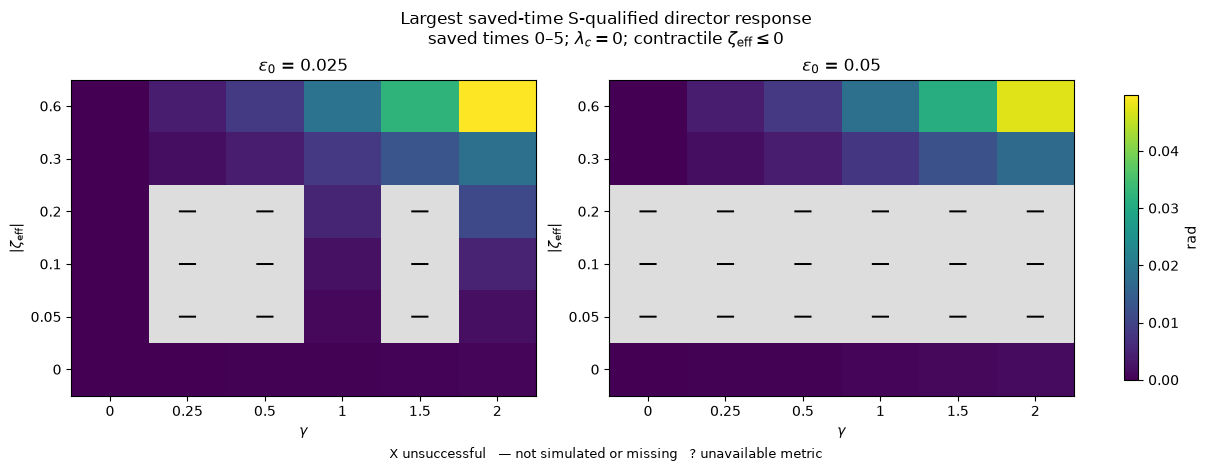

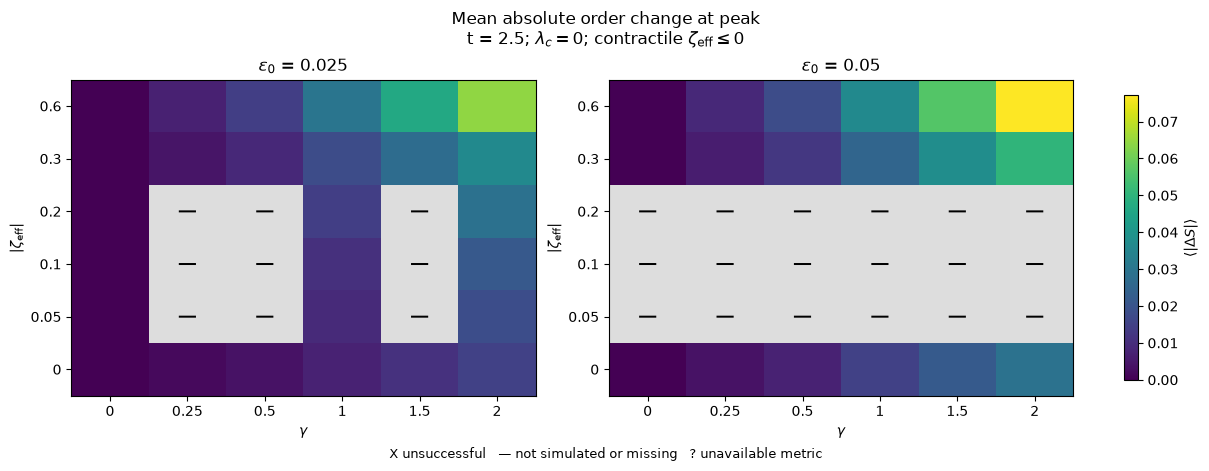

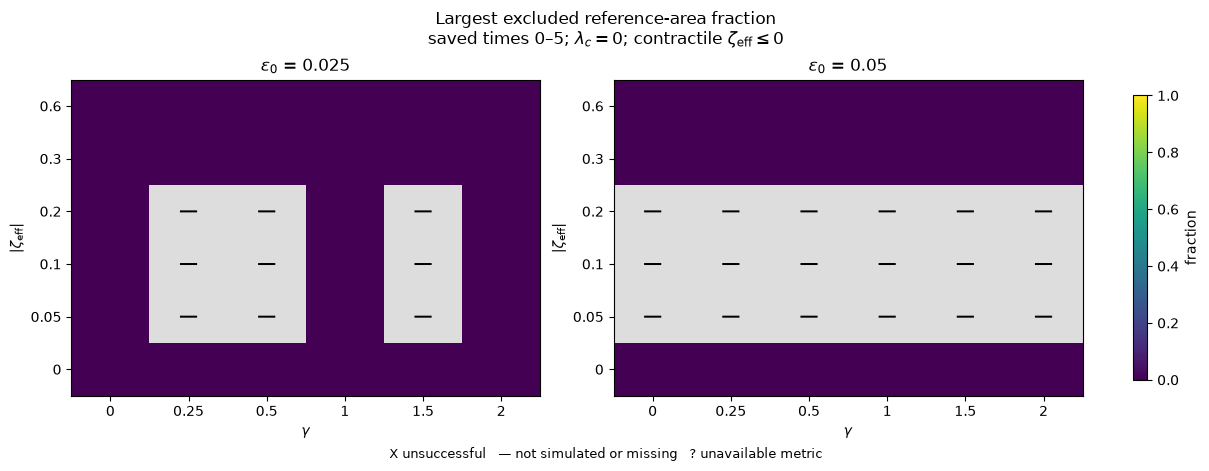

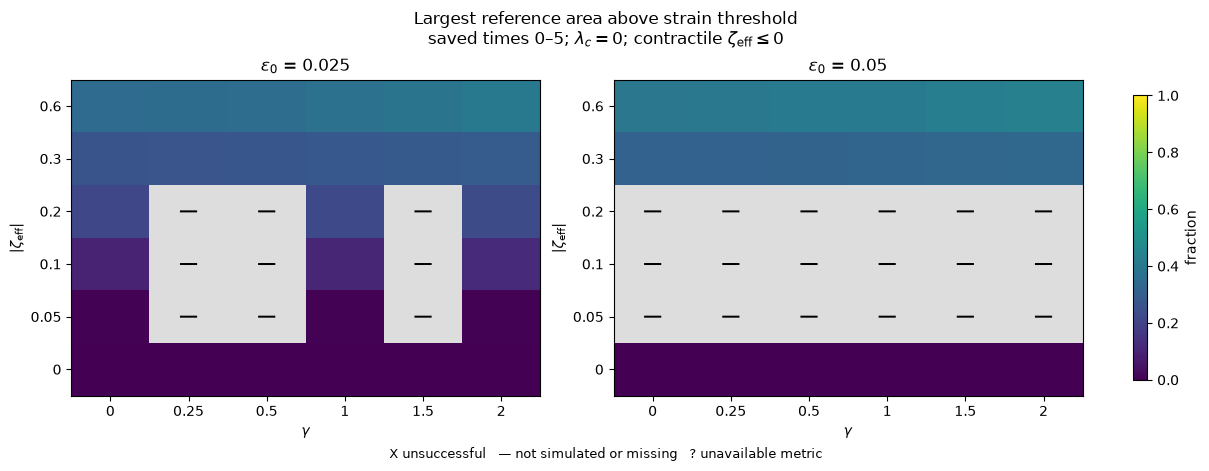

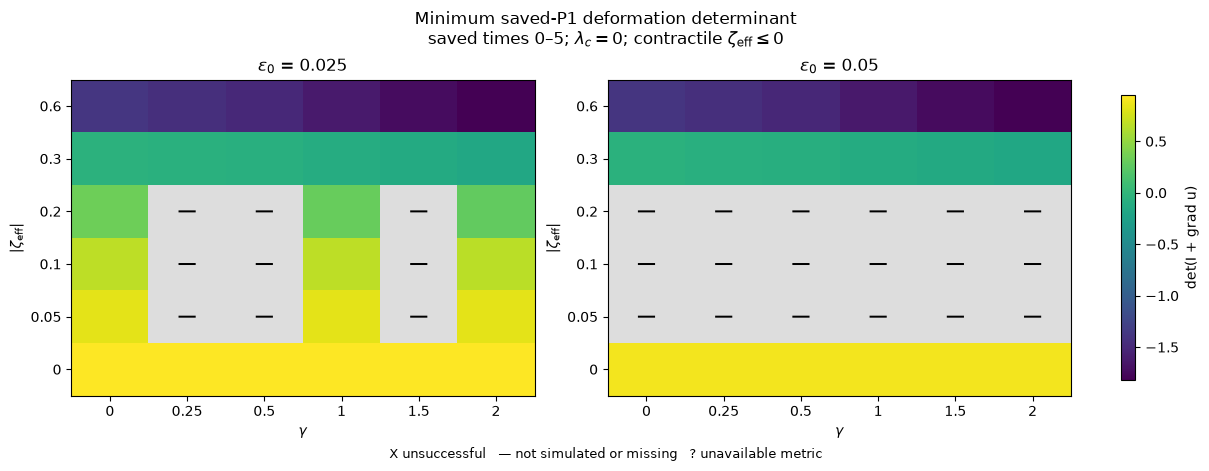

Figures saved in /mnt/c/3.Programming Apps/python of the gauds/projects/Master thesis/FEniCS code/outputs/strain_coupling/figures/sweeps/refined_AC_tend5p0/presentation_unannotated_20261105T111340_325021Z


In [24]:
def verify_presentation_cases(frame):
    records = []
    cases = dict(PRESENTATION_CASES)
    if REFINED_STUDY is not None:
        cases = {}
        for label, (epsilon0, gamma, zeta_eff) in REFINED_ANNOTATIONS.items():
            matches = frame.loc[np.isclose(frame.epsilon0, epsilon0, atol=1e-12, rtol=0) &
                                np.isclose(frame.gamma, gamma, atol=1e-12, rtol=0) &
                                np.isclose(frame.zeta_eff, zeta_eff, atol=1e-12, rtol=0)]
            if len(matches) != 1:
                raise ValueError(f"Annotation {label}: parameter tuple absent or duplicated")
            cases[label] = (int(matches.iloc[0].run_id), epsilon0, gamma, zeta_eff)
    for label, (run_id, epsilon0, gamma, zeta_eff) in cases.items():
        matches = frame.loc[frame["run_id"] == run_id]
        if len(matches) != 1:
            raise ValueError(f"Candidate {label}: ID {run_id} is not unique/present in this report. Disable MAKE_ANNOTATED_MAP for other grids.")
        row = matches.iloc[0]
        expected = dict(epsilon0=epsilon0, gamma=gamma, zeta_eff=zeta_eff)
        for key, value in expected.items():
            if not np.isclose(row[key], value, atol=1e-12, rtol=0):
                raise ValueError(f"Candidate {label}: ID {run_id} has unexpected {key}")
        folder = Path(row["run_folder"])
        if not folder.is_dir():
            portable = str(folder).replace("\\", "/")
            folder = ROOT / "outputs/strain_coupling" / portable.split("outputs/strain_coupling/", 1)[1]
        metadata = json.loads((folder / "parameters.json").read_text(encoding="utf-8"))
        for key in [*expected, *FIXED_PARAMETERS]:
            if not np.isclose(metadata[key], row[key], atol=1e-12, rtol=1e-12):
                raise ValueError(f"Candidate {label}: metadata mismatch for {key}")
        if metadata["lambda_coupling"] != 0:
            raise ValueError(f"Candidate {label}: unexpected corotation")
        record = row.to_dict()
        record.update(label=label, metadata_verified=True)
        records.append(record)
    return pd.DataFrame(records)


def plot_response_maps(annotated=False, metrics=None):
    LABELS = {"epsilon0": r"$\varepsilon_0$", "gamma": r"$\gamma$", "zeta_eff": r"$\zeta_{\mathrm{eff}}$"}
    OBSERVABLES = {
        "mean_abs_dtheta": ("Mean absolute director change at peak", r"$\langle |\Delta\theta|\rangle$ (rad)"),
        "max_abs_dtheta": ("Maximum absolute director change at peak", r"$\max |\Delta\theta|$ (rad)"),
        "mean_abs_dS": ("Mean absolute order change at peak", r"$\langle |\Delta S|\rangle$"),
        "max_time_mean_abs_dtheta": ("Largest saved-time mean director change", r"$\max_t\langle |\Delta\theta|\rangle$ (rad)"),
    }
    if True:  # Also expose new metrics as unavailable when an older report lacks them.
        OBSERVABLES.update({
            "masked_mean_abs_dtheta": ("Area-weighted director change, S-qualified cells", "rad, peak"),
            "excluded_area_fraction": ("Low-order excluded reference area", "fraction, peak"),
            "max_time_masked_mean_abs_dtheta": ("Largest saved-time S-qualified director response", "rad"),
            "max_time_excluded_area_fraction": ("Largest excluded reference-area fraction", "fraction"),
            "max_time_strain_p1": ("Maximum saved-P1 strain norm", "Frobenius norm"),
            "max_time_grad_u_p1": ("Maximum saved-P1 displacement-gradient norm", "Frobenius norm"),
            "min_time_det_F_p1": ("Minimum saved-P1 deformation determinant", "det(I + grad u)"),
            "peak_strain_area_fraction": ("Reference area above strain threshold at peak", "fraction"),
            "peak_gradient_area_fraction": ("Reference area above gradient threshold at peak", "fraction"),
            "max_time_strain_area_fraction": ("Largest reference area above strain threshold", "fraction"),
            "max_time_gradient_area_fraction": ("Largest reference area above gradient threshold", "fraction"),
        })
    if metrics is None and not PLOT_ALL_DIAGNOSTICS:
        metrics = DEFAULT_PLOT_METRICS
    if metrics is not None:
        OBSERVABLES = {key: OBSERVABLES[key] for key in metrics}
    magnitude_y = ABS_ACTIVITY_AXIS and Y_PARAMETER == "zeta_eff"
    if magnitude_y and (data["zeta_eff"] < 0).any() and (data["zeta_eff"] > 0).any():
        raise ValueError("Magnitude plots require one activity sign; use ABS_ACTIVITY_AXIS=False for mixed signs")
    if not fixed_values:
        raise ValueError("Choose at least one fixed-parameter slice")
    kind = "diagnostic" if SHOW_SCREENING_FLAGS else "presentation"
    kind += "_annotated" if annotated else "_unannotated"
    export_dir = FIGURE_DIR / datetime.now(timezone.utc).strftime(kind + "_%Y%m%dT%H%M%S_%fZ")
    if SAVE_FIGURES:
        export_dir.mkdir(parents=True, exist_ok=False)
    x_values = sorted(data[X_PARAMETER].unique())
    y_values = sorted(data[Y_PARAMETER].unique(), key=abs if magnitude_y else None)
    cmap = plt.get_cmap("viridis").copy()
    cmap.set_bad("#dddddd")
    for metric, (title, color_label) in OBSERVABLES.items():
        values = data.loc[complete, metric].dropna().to_numpy()
        vmax = float(values.max()) if values.size else 0.0
        if metric == "min_time_det_F_p1":
            vmin = float(values.min()) if values.size else 0.0
            norm = Normalize(vmin=vmin, vmax=vmax if vmax > vmin else vmin+1.0)
        elif "area_fraction" in metric:
            norm = Normalize(0, 1)
        else:
            norm = Normalize(vmin=0, vmax=vmax if vmax > 0 else 1.0)
        ncols = min(2, len(fixed_values))
        nrows = (len(fixed_values)+ncols-1)//ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4.6*nrows), squeeze=False, constrained_layout=True)
        used_axes = []
        for ax, fixed_value in zip(axes.flat, fixed_values):
            used_axes.append(ax)
            subset = data.loc[np.isclose(data[FIXED_PARAMETER], fixed_value, rtol=0, atol=1e-12)]
            lookup = subset.set_index([Y_PARAMETER, X_PARAMETER])
            matrix = np.full((len(y_values), len(x_values)), np.nan)
            annotations = []
            for iy, y in enumerate(y_values):
                for ix, x in enumerate(x_values):
                    if (y, x) not in lookup.index:
                        annotations.append((ix, iy, "—"))
                        continue
                    row = lookup.loc[(y, x)]
                    if row["status"] == "complete":
                        if np.isfinite(row[metric]):
                            matrix[iy, ix] = row[metric]
                        else:
                            annotations.append((ix, iy, "?"))
                        flag = str(row["review_flags"])
                        if SHOW_SCREENING_FLAGS and flag not in ("none", "nan") and "not assessed" not in flag:
                            ax.text(ix+.32, iy+.27, "!", color="red", fontsize=10, fontweight="bold", zorder=4)
                    else:
                        annotations.append((ix, iy, "—" if row["status"] in ("missing", "not_run") else "X"))
            im = ax.imshow(np.ma.masked_invalid(matrix), origin="lower", aspect="auto", interpolation="nearest", cmap=cmap, norm=norm)
            ax.set_xticks(range(len(x_values)), [f"{v:g}" for v in x_values])
            ax.set_yticks(range(len(y_values)), [f"{abs(v) if magnitude_y else v:g}" for v in y_values])
            ax.set_xlabel(LABELS[X_PARAMETER])
            ax.set_ylabel(r"$|\zeta_{\mathrm{eff}}|$" if magnitude_y else LABELS[Y_PARAMETER])
            ax.set_title(f"{LABELS[FIXED_PARAMETER]} = {fixed_value:g}")
            if annotated and metric == "max_time_masked_mean_abs_dtheta":
                for _, chosen in verified_candidates.iterrows():
                    if not np.isclose(chosen[FIXED_PARAMETER], fixed_value, atol=1e-12, rtol=0):
                        continue
                    ix, iy = x_values.index(chosen[X_PARAMETER]), y_values.index(chosen[Y_PARAMETER])
                    # Small corner badge leaves the failed-run X at the cell center visible.
                    ax.text(ix-.28, iy+.28, chosen["label"], ha="center", va="center",
                            color="black", fontsize=9, fontweight="bold", zorder=6,
                            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="black", linewidth=.7))
            if SHOW_SELECTED_MARKERS and metric == "max_time_masked_mean_abs_dtheta" and not annotated:
                selected = subset.loc[subset["run_id"].isin(SELECTED_RUN_IDS) & subset["status"].eq("complete")]
                for _, chosen in selected.iterrows():
                    ix, iy = x_values.index(chosen[X_PARAMETER]), y_values.index(chosen[Y_PARAMETER])
                    ax.plot(ix, iy, "o", ms=20, mfc="none", mec="white", mew=1.5)
                    ax.text(ix, iy, str(int(chosen["run_id"])), color="white", ha="center", va="center", fontsize=8)
            for ix, iy, symbol in annotations:
                ax.text(ix, iy, symbol, ha="center", va="center", fontsize=14, color="black")
        for ax in list(axes.flat)[len(fixed_values):]:
            ax.set_visible(False)
        time_label = (f"saved times 0–{data.iloc[0]['t_end']:g}" if metric.startswith(("max_time_", "min_time_"))
                      else f"t = {data.iloc[0]['target_t']:g}")
        convention = r"; contractile $\zeta_{\mathrm{eff}}\leq 0$" if magnitude_y and (data["zeta_eff"] <= 0).all() else ""
        fig.suptitle(f"{title}\n{time_label}; " + rf"$\lambda_c={data.iloc[0]['lambda_coupling']:g}$" + convention)
        fig.colorbar(im, ax=used_axes, label=color_label, shrink=0.9)
        legend = "X unsuccessful   — not simulated or missing   ? unavailable metric"
        if SHOW_SCREENING_FLAGS:
            legend += "   ! screening flag (not a phase label)"
        if annotated:
            legend += "   labels: see accompanying candidate table"
        fig.supxlabel(legend, fontsize=9)
        if SAVE_FIGURES:
            y_tag = "abs_zeta_eff" if magnitude_y else Y_PARAMETER
            name = f"{metric}_{X_PARAMETER}_vs_{y_tag}_panels"
            if annotated and metric == "max_time_masked_mean_abs_dtheta":
                name += "_annotated"
            fig.savefig(export_dir / (name + ".pdf"))
        plt.show()
        plt.close(fig)
    if SAVE_FIGURES:
        print(f"Figures saved in {export_dir}")
    if annotated and SAVE_FIGURES:
        verified_candidates.to_csv(export_dir / "verified_candidates.csv", index=False)
    return export_dir

if data is not None:
    if MAKE_ANNOTATED_MAP:
        verified_candidates = verify_presentation_cases(data)
    # Exactly one set; optional badges appear only on its primary director map.
    primary_export_dir = plot_response_maps(annotated=MAKE_ANNOTATED_MAP)


## Representative candidates, not phase labels

These rankings suggest weak, intermediate, strong, order-changing and deformation-flagged responses for inspection. A small average angle change does not prove spatial uniformity. IDs refer to the loaded report; copy desired IDs to `SELECTED_RUN_IDS`, then rerun maps and the selection cell. Numerical failures are listed separately above.


In [25]:
if data is not None:
    good = data.loc[complete].copy()
    score = "max_time_mean_abs_dtheta" if good["max_time_mean_abs_dtheta"].notna().all() else "mean_abs_dtheta"
    candidates = []
    def add_candidates(label, rows):
        for _, row in rows.iterrows():
            record = row.to_dict()
            record["selection_reason"] = label
            candidates.append(record)
    if not good.empty:

        middle = (good[score] - good[score].median()).abs().nsmallest(1).index

        add_candidates("Strongest mean director response", good.nlargest(3, score))
        add_candidates("Largest peak order change", good.nlargest(2, "mean_abs_dS"))
        add_candidates("Smallest det(F): inspect inversion", good.dropna(subset=["min_time_det_F_p1"]).nsmallest(2, "min_time_det_F_p1"))
        spread = good["max_abs_dtheta"] - good["mean_abs_dtheta"]
        add_candidates("Largest peak max-minus-mean angle: inspect spatial field", good.loc[spread.nlargest(2).index])
        add_candidates("Largest saved-P1 strain: inspect model validity", good.dropna(subset=["max_time_strain_p1"]).nlargest(2, "max_time_strain_p1"))
        flags = good["review_flags"].fillna("not assessed").ne("none")
        add_candidates("Screening flag: manual review", good.loc[flags].nlargest(3, "max_time_grad_u_p1"))
        add_candidates("Weakest mean director response", good.nsmallest(1, score))
        add_candidates("Intermediate mean director response", good.loc[middle])
        candidate_table = pd.DataFrame(candidates)
        reasons = candidate_table.groupby("run_id")["selection_reason"].agg(lambda x: "; ".join(dict.fromkeys(x)))
        candidate_table = candidate_table.drop_duplicates("run_id").copy()
        candidate_table["selection_reason"] = candidate_table["run_id"].map(reasons)
        candidate_table = candidate_table.head(CANDIDATE_LIMIT)
        display(candidate_table[["run_id", "selection_reason", *PARAMETERS, score,
                                 "time_max_mean_abs_dtheta", "mean_abs_dS", "max_time_strain_p1",
                                 "max_time_grad_u_p1", "min_time_det_F_p1", "min_time_S", "max_time_S",
                                 "review_flags", "run_folder"]])
    else:
        print("No completed cases to rank yet.")

# Additional compact ranking: strict screening pass first, not physical validation.
if data is not None and REFINED_STUDY is not None:
    ranked = data.loc[data.status.eq("complete")].copy()
    ranked["screen_pass"] = ((ranked.max_time_strain_p1 <= STRAIN_REVIEW) &
                             (ranked.max_time_grad_u_p1 <= GRAD_REVIEW) &
                             (ranked.min_time_det_F_p1 > 0) &
                             (ranked.max_time_excluded_area_fraction == 0) &
                             (ranked.max_time_S <= S_HIGH_REVIEW))
    ranked = ranked.sort_values(["screen_pass", "max_time_excluded_area_fraction", "max_time_masked_mean_abs_dtheta"],
                                ascending=[False, True, False], na_position="last")
    ranked["director_response_rad"] = ranked["max_time_masked_mean_abs_dtheta"]
    ranked["director_response_deg"] = np.degrees(ranked["director_response_rad"])
    ranked["screening_status"] = np.select(
        [ranked.screen_pass, ranked.min_time_det_F_p1.le(0)],
        ["Passes screening; not physically validated", "P1 inversion: nonphysical geometry preview"],
        default="Flagged: inspect local P1 / order diagnostics")
    cols = ["run_id", *PARAMETERS, "director_response_rad", "director_response_deg",
            "min_time_S", "max_time_S", "max_time_excluded_area_fraction",
            "max_time_strain_area_fraction", "max_time_gradient_area_fraction",
            "min_time_det_F_p1", "screening_status", "review_flags", "run_folder"]
    print("Screening-passing candidates first; no automatic animation selection:")
    display(ranked[cols].head(CANDIDATE_LIMIT))
    print("Flagged high-response comparison cases (not physically validated):")
    display(ranked.loc[~ranked.screen_pass].sort_values("director_response_rad", ascending=False)[cols].head(4))


,run_id,selection_reason,epsilon0,gamma,zeta_eff,max_time_mean_abs_dtheta,time_max_mean_abs_dtheta,mean_abs_dS,max_time_strain_p1,max_time_grad_u_p1,min_time_det_F_p1,min_time_S,max_time_S,review_flags,run_folder
0,17,Strongest mean director response; Largest peak...,0.025,2.0,-0.60,0.049678,5.0,6.415869e-02,2.767541,3.973324,-1.817488,0.913026,1.431560,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...
1,35,Strongest mean director response; Largest peak...,0.050,2.0,-0.60,0.047187,5.0,7.706861e-02,2.790863,3.958432,-1.817289,0.920894,1.436783,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...
2,14,Strongest mean director response; Screening fl...,0.025,1.5,-0.60,0.032311,5.0,4.639096e-02,2.607365,3.849929,-1.729585,0.947884,1.324820,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...
14,0,Weakest mean director response,0.025,0.0,0.00,0.000000,0.0,2.063735e-14,0.077016,0.138480,0.945197,1.000000,1.000000,none,/mnt/c/3.Programming Apps/python of the gauds/...
15,42,Intermediate mean director response,0.025,2.0,-0.05,0.002005,5.0,1.809944e-02,0.202152,0.259038,0.828756,0.998461,1.043390,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...


Screening-passing candidates first; no automatic animation selection:


,run_id,epsilon0,gamma,zeta_eff,director_response_rad,director_response_deg,min_time_S,max_time_S,max_time_excluded_area_fraction,max_time_strain_area_fraction,max_time_gradient_area_fraction,min_time_det_F_p1,screening_status,review_flags,run_folder
15,15,0.025,2.00,0.0,0.000757,0.043386,0.997610,1.021822,0.0,0.000000,0.000000,0.945197,Passes screening; not physically validated,none,/mnt/c/3.Programming Apps/python of the gauds/...
12,12,0.025,1.50,0.0,0.000573,0.032851,0.998211,1.016463,0.0,0.000000,0.000000,0.945197,Passes screening; not physically validated,none,/mnt/c/3.Programming Apps/python of the gauds/...
9,9,0.025,1.00,0.0,0.000386,0.022113,0.998809,1.011041,0.0,0.000000,0.000000,0.945197,Passes screening; not physically validated,none,/mnt/c/3.Programming Apps/python of the gauds/...
6,6,0.025,0.50,0.0,0.000195,0.011165,0.999406,1.005554,0.0,0.000000,0.000000,0.945197,Passes screening; not physically validated,none,/mnt/c/3.Programming Apps/python of the gauds/...
3,3,0.025,0.25,0.0,0.000098,0.005610,0.999703,1.002786,0.0,0.000000,0.000000,0.945197,Passes screening; not physically validated,none,/mnt/c/3.Programming Apps/python of the gauds/...
0,0,0.025,0.00,0.0,0.000000,0.000000,1.000000,1.000000,0.0,0.000000,0.000000,0.945197,Passes screening; not physically validated,none,/mnt/c/3.Programming Apps/python of the gauds/...
17,17,0.025,2.00,-0.6,0.049678,2.846343,0.913026,1.431560,0.0,0.403035,0.351776,-1.817488,P1 inversion: nonphysical geometry preview,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...
35,35,0.050,2.00,-0.6,0.047187,2.703628,0.920894,1.436783,0.0,0.437298,0.350419,-1.817289,P1 inversion: nonphysical geometry preview,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...
14,14,0.025,1.50,-0.6,0.032311,1.851288,0.947884,1.324820,0.0,0.385080,0.324397,-1.729585,P1 inversion: nonphysical geometry preview,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...
32,32,0.050,1.50,-0.6,0.030990,1.775581,0.953641,1.329462,0.0,0.426566,0.334563,-1.732210,P1 inversion: nonphysical geometry preview,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...


Flagged high-response comparison cases (not physically validated):


,run_id,epsilon0,gamma,zeta_eff,director_response_rad,director_response_deg,min_time_S,max_time_S,max_time_excluded_area_fraction,max_time_strain_area_fraction,max_time_gradient_area_fraction,min_time_det_F_p1,screening_status,review_flags,run_folder
17,17,0.025,2.0,-0.6,0.049678,2.846343,0.913026,1.431560,0.0,0.403035,0.351776,-1.817488,P1 inversion: nonphysical geometry preview,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...
35,35,0.050,2.0,-0.6,0.047187,2.703628,0.920894,1.436783,0.0,0.437298,0.350419,-1.817289,P1 inversion: nonphysical geometry preview,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...
14,14,0.025,1.5,-0.6,0.032311,1.851288,0.947884,1.324820,0.0,0.385080,0.324397,-1.729585,P1 inversion: nonphysical geometry preview,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...
32,32,0.050,1.5,-0.6,0.030990,1.775581,0.953641,1.329462,0.0,0.426566,0.334563,-1.732210,P1 inversion: nonphysical geometry preview,saved-P1 strain norm > 0.1; saved-P1 gradient ...,/mnt/c/3.Programming Apps/python of the gauds/...


## Transfer explicitly selected runs to the visualization notebook

Set `SELECTED_RUN_IDS` to IDs from the currently loaded report, then run the next cell. Optional `CUSTOM_CASE_LABELS` maps those IDs to short labels. A new study-specific manifest records the exact report, IDs, parameters and folders; no case is selected automatically. Open `strain_coupling_visualization.ipynb`, choose `SELECTION_MODE="custom"`, and paste the printed `SELECTION_MANIFEST` assignment. IDs are scoped by study and report, not global. The original postprocessor is not used.


In [26]:
from IPython.display import FileLink

def local_run_folder(value):
    folder = Path(value)
    if folder.is_dir():
        return folder
    # Allow a WSL CSV to be inspected from the same Windows checkout.
    portable = str(value).replace("\\", "/")
    marker = "outputs/strain_coupling/"
    if marker in portable:
        candidate = ROOT / marker / portable.split(marker, 1)[1]
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError(f"Run folder not found: {value}")

def export_selection(frame, ids, labels=None, directory=None):
    if REFINED_STUDY not in ("F", "AC"):
        raise ValueError("Custom transfer currently supports the F and AC studies")
    if len(LOADED_REPORTS) != 1 or LOADED_STUDY_TAG != STUDY_TAG:
        raise ValueError("Reload exactly one report for the configured study")
    if not ids or len(ids) != len(set(ids)):
        raise ValueError("Select distinct run IDs explicitly")
    labels = labels or {}
    records = []
    for run_id in ids:
        rows = frame.loc[frame.run_id.eq(run_id)]
        if len(rows) != 1 or rows.iloc[0].status != "complete":
            raise ValueError(f"ID {run_id}: choose a completed run in this report")
        row = rows.iloc[0]
        folder = local_run_folder(row.run_folder)
        metadata = json.loads((folder / "parameters.json").read_text(encoding="utf-8"))
        keys = [*PARAMETERS, *FIXED_PARAMETERS, "L", "d0"]
        parameters = {key: float(row[key]) for key in keys}
        if any(not np.isclose(metadata[key], value, atol=1e-12, rtol=1e-12) for key, value in parameters.items()):
            raise ValueError(f"ID {run_id}: metadata differs from loaded report")
        label = labels.get(run_id, f"{REFINED_STUDY}_{int(run_id):03d}")
        import re
        if not isinstance(label, str) or not re.fullmatch(r"[A-Za-z0-9_-]+", label):
            raise ValueError("Labels must contain only letters, digits, underscores or hyphens")
        records.append(dict(label=label, run_id=int(run_id), parameters=parameters,
                            run_folder=folder.resolve().relative_to(ROOT.resolve()).as_posix()))
    if len({r["label"] for r in records}) != len(records):
        raise ValueError("Case labels must be unique")
    report = LOADED_REPORTS[0]
    import hashlib
    manifest = dict(schema_version=1, study=REFINED_STUDY, study_tag=STUDY_TAG,
                    source_report=report.relative_to(ROOT.resolve()).as_posix(),
                    report_sha256=hashlib.sha256(report.read_bytes()).hexdigest(), cases=records)
    directory = ROOT / "outputs/strain_coupling/selections" / STUDY_TAG if directory is None else Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / datetime.now(timezone.utc).strftime("selection_%Y%m%dT%H%M%S_%fZ.json")
    with path.open("x", encoding="utf-8") as stream:
        json.dump(manifest, stream, indent=2)
    return path

if data is not None and SELECTED_RUN_IDS:
    manifest_path = export_selection(data, SELECTED_RUN_IDS, CUSTOM_CASE_LABELS)
    selected_runs = data.loc[data.run_id.isin(SELECTED_RUN_IDS)]
    display(selected_runs[["run_id", *PARAMETERS, "status", "run_folder"]])
    display(FileLink("strain_coupling_visualization.ipynb"))
    print('SELECTION_MODE = "custom"')
    print(f"SELECTION_MANIFEST = ROOT / {manifest_path.relative_to(ROOT).as_posix()!r}")
else:
    print("No selection exported. Set SELECTED_RUN_IDS after reviewing this study's tables.")


No selection exported. Set SELECTED_RUN_IDS after reviewing this study's tables.


## Optional epsilon0 = 0.30 activity comparison

Run the configuration and sweep-helper definitions (cells 2, 4 and 5 counting markdown), then this cell in preview mode. This scans zeta_eff = 0, -0.3, -0.6 at gamma=-8, using the existing fixed settings. Set EXTRA_MODE="run" when ready. The completed zero-activity case is reused after verification. The separate contractile_activity output/report name preserves the original single-case study. Main-study configuration is restored afterward.


In [27]:
EXTRA_MODE = "skip"  # Disabled: "skip". Later choose "preview", "run", or "analyze".
EXTRA_RETRY_FAILED = False
EXTRA_ZETA_VALUES = [0.0, -0.3, -0.6]  # Contractile activity; gamma=-8, epsilon0=0.30.

if EXTRA_MODE == "skip":
    print("Optional epsilon0=0.30 activity scan disabled; no simulation or output created.")
else:
    if FIXED["A"] != 1 or FIXED["lambda_coupling"] != 0:
        raise ValueError("Keep A=1 and lambda_coupling=0")
    extra_tag = "exploratory_eps0p30_gamm8_contractile_activity_tend" + str(FIXED["t_end"]).replace(".", "p")
    extra_config = dict(
        STUDY="scan", BASE=dict(epsilon0=0.30, gamma=-8.0, zeta_eff=0.0),
        SCAN_PARAMETER="zeta_eff", SCAN_VALUES={"zeta_eff": EXTRA_ZETA_VALUES},
        OUTPUT_ROOT=ROOT / "outputs/strain_coupling/sweeps" / extra_tag,
        REPORT_PREFIX="strain_coupling_" + extra_tag,
        BATCH_SIZE=None, BATCH_INDEX=0, RETRY_FAILED=EXTRA_RETRY_FAILED,
    )
    saved_config = {key: globals()[key] for key in extra_config}
    try:
        globals().update(extra_config)
        EXTRA_REPORT = run_sweep(EXTRA_MODE)  # Existing machinery; three cases, with completed matching runs reused.
    finally:
        globals().update(saved_config)


Optional epsilon0=0.30 activity scan disabled; no simulation or output created.
